Required libraries for the project

In [1]:
import pandas as pd
import numpy as np
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns



Importing the csv files, creating a function to check the names of the columns in each csv file, and printing the names of the columns.  

In [2]:
results = pd.read_csv('results.csv')
shootouts = pd.read_csv('shootouts.csv')
goalscorers = pd.read_csv('goalscorers.csv')


def print_columns(df, name):
    print(f"{name} columns: {df.columns.tolist()}")

print_columns(results, 'results')
print_columns(shootouts, 'shootouts')
print_columns(goalscorers, 'goalscorers')   


results columns: ['date', 'home_team', 'away_team', 'home_score', 'away_score', 'tournament', 'city', 'country', 'neutral']
shootouts columns: ['date', 'home_team', 'away_team', 'winner', 'first_shooter']
goalscorers columns: ['date', 'home_team', 'away_team', 'team', 'scorer', 'minute', 'own_goal', 'penalty']


Checking the general organization of the results dataframe. Checking the data input in the columns and see if there are changes between the beginning and end of the data. 

In [3]:
print(results.head())
print(results.tail())

         date home_team away_team  home_score  away_score tournament     city  \
0  1872-11-30  Scotland   England           0           0   Friendly  Glasgow   
1  1873-03-08   England  Scotland           4           2   Friendly   London   
2  1874-03-07  Scotland   England           2           1   Friendly  Glasgow   
3  1875-03-06   England  Scotland           2           2   Friendly   London   
4  1876-03-04  Scotland   England           3           0   Friendly  Glasgow   

    country  neutral  
0  Scotland    False  
1   England    False  
2  Scotland    False  
3   England    False  
4  Scotland    False  
             date    home_team    away_team  home_score  away_score  \
48330  2025-06-10       Serbia      Andorra           3           0   
48331  2025-06-10       Latvia      Albania           1           1   
48332  2025-06-10  New Zealand      Ukraine           1           2   
48333  2025-06-10       Canada  Ivory Coast           0           0   
48334  2025-06-10   

Similar process and reasoning for checking the results dataframe. I plan to use this dataframe later with the results data for exploring shootouts in the World Cup. 

In [4]:
print(shootouts.head())
print(shootouts.tail())

         date    home_team         away_team       winner first_shooter
0  1967-08-22        India            Taiwan       Taiwan           NaN
1  1971-11-14  South Korea  Vietnam Republic  South Korea           NaN
2  1972-05-07  South Korea              Iraq         Iraq           NaN
3  1972-05-17     Thailand       South Korea  South Korea           NaN
4  1972-05-19     Thailand          Cambodia     Thailand           NaN
           date   home_team    away_team      winner first_shooter
642  2024-07-06     Uruguay       Brazil     Uruguay       Uruguay
643  2024-07-13      Canada      Uruguay     Uruguay        Canada
644  2024-09-08  Tajikistan  Philippines  Tajikistan           NaN
645  2024-09-10    Cambodia    Sri Lanka   Sri Lanka      Cambodia
646  2025-06-08    Portugal        Spain    Portugal      Portugal


Same reasoning as results and shootouts. Checking for differences in how data is organized and the beginning of this data starts approximately 40 years after some of the earliest data in the results csv. 

In [5]:
print(goalscorers.head())
print(goalscorers.tail())

         date  home_team away_team       team            scorer  minute  \
0  1916-07-02      Chile   Uruguay    Uruguay   José Piendibene    44.0   
1  1916-07-02      Chile   Uruguay    Uruguay  Isabelino Gradín    55.0   
2  1916-07-02      Chile   Uruguay    Uruguay  Isabelino Gradín    70.0   
3  1916-07-02      Chile   Uruguay    Uruguay   José Piendibene    75.0   
4  1916-07-06  Argentina     Chile  Argentina     Alberto Ohaco     2.0   

   own_goal  penalty  
0     False    False  
1     False    False  
2     False    False  
3     False    False  
4     False    False  
             date  home_team away_team       team            scorer  minute  \
44357  2024-07-13     Canada   Uruguay    Uruguay       Luis Suárez    90.0   
44358  2024-07-14  Argentina  Colombia  Argentina  Lautaro Martínez   112.0   
44359  2024-07-14      Spain   England      Spain     Nico Williams    47.0   
44360  2024-07-14      Spain   England    England       Cole Palmer    73.0   
44361  2024-07-1

In [6]:
# Function to print the shape of the dataframes
def print_shape(df, name):
    print(f"{name} shape: {df.shape}")

print_shape(results, 'results')

results shape: (48335, 9)


In [7]:
# Function to print the dtypes
def print_dtypes(df, name):
    print(f"{name} dtypes:\n{df.dtypes}\n")

print_dtypes(shootouts, 'shootouts')

shootouts dtypes:
date             str
home_team        str
away_team        str
winner           str
first_shooter    str
dtype: object



In [8]:
# Function to check for null values in the dataframes
def is_null(df):
    print(df.isnull().sum())

is_null(goalscorers)

date           0
home_team      0
away_team      0
team           0
scorer        49
minute       259
own_goal       0
penalty        0
dtype: int64


In [9]:
# Function to call the info method on the dataframes
def print_info(df, name):
    print(f"{name} info: {df.info()}")

print_info(results, 'results')

<class 'pandas.DataFrame'>
RangeIndex: 48335 entries, 0 to 48334
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   date        48335 non-null  str  
 1   home_team   48335 non-null  str  
 2   away_team   48335 non-null  str  
 3   home_score  48335 non-null  int64
 4   away_score  48335 non-null  int64
 5   tournament  48335 non-null  str  
 6   city        48335 non-null  str  
 7   country     48335 non-null  str  
 8   neutral     48335 non-null  bool 
dtypes: bool(1), int64(2), str(6)
memory usage: 3.0 MB
results info: None


This function was created to quickly call describe of any dataframes. The data is rounded for readability. 

In [10]:
# Function to call the describe method on the data frames. I rounded the output 2 decimal places for readability.
def print_describe(df, name):
    print(f"{name} describe: {df.describe().round(2)}")

print_describe(results, 'results')


results describe:        home_score  away_score
count    48335.00    48335.00
mean         1.76        1.18
std          1.77        1.40
min          0.00        0.00
25%          1.00        0.00
50%          1.00        1.00
75%          2.00        2.00
max         31.00       21.00


Standardizing the dates of the three tables for combining the tables since the dates are going to be the primary key for each of the new tables. 

In [11]:
#Function to convert a specified column in a DataFrame to datetime format in case I add any dataframes later


def to_datetime(df, column='date', date_format='%Y-%m-%d'):
    """
    Converts a specified column in a DataFrame to datetime format.
    """
    df[column] = pd.to_datetime(df[column], format=date_format)
    return df


to_datetime(results)
to_datetime(shootouts)
to_datetime(goalscorers)

,date,home_team,away_team,team,scorer,minute,own_goal,penalty
0,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,44.0,False,False
1,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,55.0,False,False
2,1916-07-02,Chile,Uruguay,Uruguay,Isabelino Gradín,70.0,False,False
3,1916-07-02,Chile,Uruguay,Uruguay,José Piendibene,75.0,False,False
4,1916-07-06,Argentina,Chile,Argentina,Alberto Ohaco,2.0,False,False
...,...,...,...,...,...,...,...,...
44357,2024-07-13,Canada,Uruguay,Uruguay,Luis Suárez,90.0,False,False
44358,2024-07-14,Argentina,Colombia,Argentina,Lautaro Martínez,112.0,False,False
44359,2024-07-14,Spain,England,Spain,Nico Williams,47.0,False,False
44360,2024-07-14,Spain,England,England,Cole Palmer,73.0,False,False


I am creating a datafram called results_wc to get extract only matches that were part of the World Cup tournament. The goal is to count the number of countries that have played in the World Cup over the courst of the tournament as the tournament expanded over the twentieth century. 

In the opening line of code, copilot suggested using .copy() after I received the following message in the output when I ran the code without .copy() at the end.

A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

Since this is new I used Bing to research this method to understand why it was included and am including the explanation I found below from geeks for geeks. 
    "The copy() method in Python is used to create a shallow copy of a list. This means that the method creates a new list containing the same elements as the original list but maintains its own identity in memory. It's useful when you want to ensure that changes to the new list do not affect the original list and vice versa."

After initially trying to count nunique of home and away teams, I realized after researching that it would be best to use pd.concat for the home and away team columns to combine them into one home team column to eliminate duplicate countries from the count. Copilot also pointed out there were countries that were always the away team in the tournament and this ensured they would be included in the count.



In [12]:
# Creating a new dataframe only from the results dataframe to get matches that only involve the FIFA World Cup
results_wc = results[results['tournament'] == 'FIFA World Cup'].copy()


# Extracting the year from the date column to group by year
results_wc['year'] = results_wc['date'].dt.year

# Concatenate the home and away teams into one column and keeping the year to count unique teams
teams = pd.concat([
        results_wc[['year', 'home_team']],
        results_wc[['year', 'away_team']].rename(columns={'away_team': 'home_team'})
])



# Grouping by year and counting the number of unique home teams that participated in each World Cup and renaming the column to countries_count
countries_count = teams.groupby('year')['home_team'].nunique().reset_index(name= 'countries')

countries_count


,year,countries
0,1930,13
1,1934,16
2,1938,15
3,1950,13
4,1954,16
5,1958,16
6,1962,16
7,1966,16
8,1970,16
9,1974,16


Graph of the World cup tournament from 1930-2022. When creating this graph, I initially was using pyplot from matplotlib, but chose to switch to sns because I personally found modifying color through sns to be easier. 

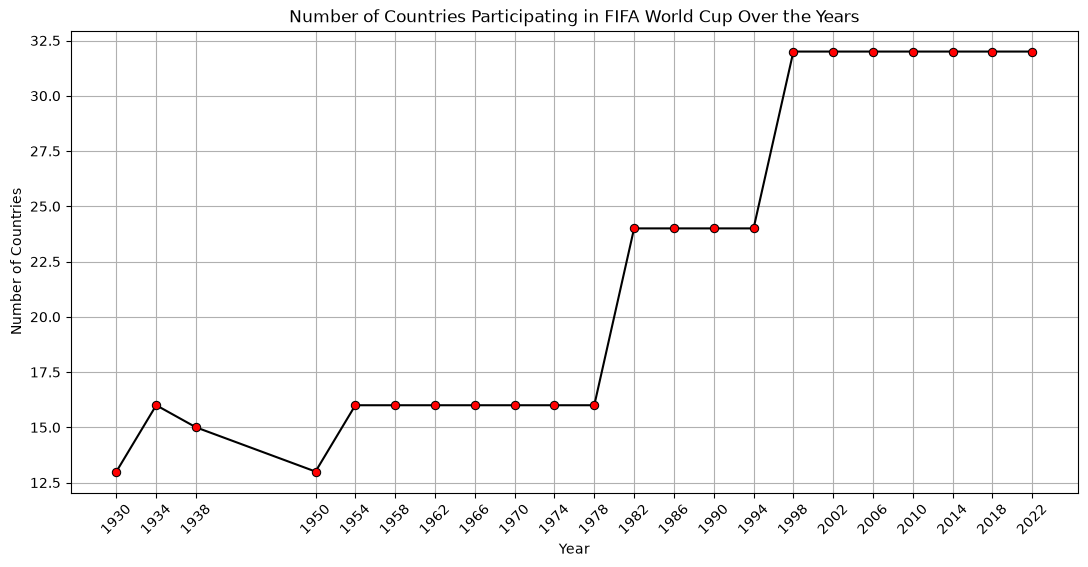

In [13]:
#Create line graph from countries_count dataframe
plt.figure(figsize=(13, 6))
sns.lineplot(data=countries_count, x='year', y='countries', color='black', marker='o', markerfacecolor='red', markeredgecolor='black',)
plt.title('Number of Countries Participating in FIFA World Cup Over the Years')
plt.xlabel('Year')
plt.ylabel('Number of Countries')
plt.xticks(countries_count['year'], rotation=45)
plt.grid(True)
plt.savefig('countries_participating.png')
plt.show()

Creating tables in SQL and joining the tables together after creating the table. Chose to use a composite key to avoid conflicts by only using date in case there were multiple matches on the same day.  

In [14]:
conn = sqlite3.connect('your_database.db')

conn.execute("DROP TABLE IF EXISTS results;")
conn.execute("DROP TABLE IF EXISTS shootouts;")

#Create tables and define primary key
conn.execute("""
CREATE TABLE results (
    date TEXT,
    home_team TEXT,
    away_team TEXT,
    home_score INTEGER,
    away_score INTEGER,
    tournament TEXT,
    city TEXT,
    country TEXT,
    neutral BOOLEAN,
    PRIMARY KEY (date, home_team, away_team)
);
""")
conn.execute("""
CREATE TABLE shootouts (
    date TEXT,
    home_team TEXT,
    away_team TEXT,
    winner TEXT,
    first_shooter TEXT,
    PRIMARY KEY (date, home_team, away_team)
);
""")


#Drop duplicates since I am using a composite primary key
results_unique = results.drop_duplicates(subset=['date', 'home_team', 'away_team'])
shootouts_unique = shootouts.drop_duplicates(subset=['date', 'home_team', 'away_team'])

#
results_unique.to_sql('results', conn, if_exists='append', index=False)
shootouts_unique.to_sql('shootouts', conn, if_exists='append', index=False)

# Joins results with shootouts tables for FIFA World Cup matches
WC_results = """

SELECT results.date AS match_date,
    results.home_team,
    results.away_team,
    results.home_score,
    results.away_score,
    results.tournament,
    shootouts.winner
FROM results
LEFT JOIN shootouts
ON results.date = shootouts.date
AND results.home_team = shootouts.home_team
AND results.away_team = shootouts.away_team
WHERE results.tournament = 'FIFA World Cup';
"""

df_WC = pd.read_sql_query(WC_results, conn)
print(df_WC.head())

conn.close()


            match_date  home_team      away_team  home_score  away_score  \
0  1930-07-13 00:00:00    Belgium  United States           0           3   
1  1930-07-13 00:00:00     France         Mexico           4           1   
2  1930-07-14 00:00:00     Brazil     Yugoslavia           1           2   
3  1930-07-14 00:00:00       Peru        Romania           1           3   
4  1930-07-15 00:00:00  Argentina         France           1           0   

       tournament winner  
0  FIFA World Cup    NaN  
1  FIFA World Cup    NaN  
2  FIFA World Cup    NaN  
3  FIFA World Cup    NaN  
4  FIFA World Cup    NaN  


In [15]:
#Join results with shootouts for later analysis.

#Create a SQLite database and store the DataFrames
conn = sqlite3.connect('your_database.db')
results.to_sql('results', conn, if_exists='replace', index=False)
shootouts.to_sql('shootouts', conn, if_exists='replace', index=False)

#SQL query to join results with shootouts
# Fix: match on date AND both team names. Matching on date alone paired every shootout with every other game played that same day.
#Originally had trouble joining the tables due to different date formats, but figured it out when meeting with a mentor.
results_join = """SELECT *
FROM results
INNER JOIN shootouts
ON results.date = shootouts.date
AND results.home_team = shootouts.home_team
AND results.away_team = shootouts.away_team;
"""

#Execute the query and load the results into a DataFrame
df_results_join = pd.read_sql_query(results_join, conn)
print(df_results_join.head())
print(f"Shootouts: {len(shootouts)} rows, joined rows: {len(df_results_join)}")
conn.close()


                  date    home_team         away_team  home_score  away_score  \
0  1967-08-22 00:00:00        India            Taiwan           1           1   
1  1971-11-14 00:00:00  South Korea  Vietnam Republic           1           1   
2  1972-05-07 00:00:00  South Korea              Iraq           0           0   
3  1972-05-17 00:00:00     Thailand       South Korea           1           1   
4  1972-05-19 00:00:00     Thailand          Cambodia           2           2   

           tournament          city   country  neutral                 date  \
0  Merdeka Tournament  Kuala Lumpur  Malaysia        1  1967-08-22 00:00:00   
1          King's Cup       Bangkok  Thailand        1  1971-11-14 00:00:00   
2       AFC Asian Cup       Bangkok  Thailand        1  1972-05-07 00:00:00   
3       AFC Asian Cup       Bangkok  Thailand        0  1972-05-17 00:00:00   
4       AFC Asian Cup       Bangkok  Thailand        0  1972-05-19 00:00:00   

     home_team         away_team      

In [16]:
print(df_results_join.tail(15))

                    date                 home_team  \
631  2024-03-26 00:00:00                     Wales   
632  2024-03-26 00:00:00                   Georgia   
633  2024-03-26 00:00:00    British Virgin Islands   
634  2024-03-26 00:00:00  Turks and Caicos Islands   
635  2024-06-11 00:00:00                 Lithuania   
636  2024-07-01 00:00:00                  Portugal   
637  2024-07-04 00:00:00                 Argentina   
638  2024-07-05 00:00:00                  Portugal   
639  2024-07-05 00:00:00                 Venezuela   
640  2024-07-06 00:00:00                   England   
641  2024-07-06 00:00:00                   Uruguay   
642  2024-07-13 00:00:00                    Canada   
643  2024-09-08 00:00:00                Tajikistan   
644  2024-09-10 00:00:00                  Cambodia   
645  2025-06-08 00:00:00                  Portugal   

                        away_team  home_score  away_score  \
631                        Poland           0           0   
632          

In [17]:
# Create a new SQLite connection and dataframe using the results and shootouts tables with only matches from FIFA World Cup matches.
conn = sqlite3.connect('your_database.db')
results.to_sql('results', conn, if_exists='replace', index=False)
shootouts.to_sql('shootouts', conn, if_exists='replace', index=False)


# Fix: count the World Cup matches BEFORE the join so I can check the join didn't add or lose rows.
wc_match_count = (results['tournament'] == 'FIFA World Cup').sum()
print(f"World Cup matches before the join: {wc_match_count}")

# Fix: join on date AND both team names. Joining on date alone duplicated matches whenever
# two shootouts happened on the same day (2018 and 2022 showed 66 matches instead of 64).
results_WC = """SELECT results.date AS match_date,
    results.home_team,
    results.away_team,
    results.home_score,
    results.away_score,
    results.tournament,
    shootouts.winner
FROM results
LEFT JOIN shootouts
ON results.date = shootouts.date
AND results.home_team = shootouts.home_team
AND results.away_team = shootouts.away_team
WHERE results.tournament = 'FIFA World Cup';
"""

df_WC = pd.read_sql_query(results_WC, conn)
print(df_WC.head())

conn.close()

print(df_WC.shape)

# Fix: row-count check AFTER the join. A LEFT JOIN should keep exactly one row per World Cup match.
print(f"World Cup rows after the join: {len(df_WC)}")
assert len(df_WC) == wc_match_count, "The join added or lost rows - check the join keys"

#convert the date column to datetime
df_WC['match_date'] = pd.to_datetime(df_WC['match_date'], errors='coerce')

World Cup matches before the join: 964
            match_date  home_team      away_team  home_score  away_score  \
0  1930-07-13 00:00:00    Belgium  United States           0           3   
1  1930-07-13 00:00:00     France         Mexico           4           1   
2  1930-07-14 00:00:00     Brazil     Yugoslavia           1           2   
3  1930-07-14 00:00:00       Peru        Romania           1           3   
4  1930-07-15 00:00:00  Argentina         France           1           0   

       tournament winner  
0  FIFA World Cup    NaN  
1  FIFA World Cup    NaN  
2  FIFA World Cup    NaN  
3  FIFA World Cup    NaN  
4  FIFA World Cup    NaN  
(964, 7)
World Cup rows after the join: 964


In [18]:
#This was the suggestion from copilot - 
country_counts = df_WC['home_team'].value_counts().add(df_WC['away_team'].value_counts(), fill_value=0)
# Fix: adding the two nunique counts counted a country twice if it was ever both home and away team.
# Combining both columns first and then counting gives each country once.
country_count = pd.concat([df_WC['home_team'], df_WC['away_team']]).nunique()
print(f"Total number of unique countries in FIFA World Cup matches: {country_count}")
print("Number of matches per country:")
print(country_counts.sort_values(ascending=False).head(10))

Total number of unique countries in FIFA World Cup matches: 82
Number of matches per country:
home_team
Brazil         114.0
Germany        112.0
Argentina       88.0
Italy           83.0
England         74.0
France          73.0
Spain           67.0
Mexico          60.0
Uruguay         59.0
Netherlands     55.0
Name: count, dtype: float64


This is a merge of goalscorers and results to get the top 20 goal scorers for the tournament. For output readability, I pulled only the columns date, home_team, and away_team from the resulst dataframe and performed an inner merge using on the same columns in goalscorers to get only the World Cup game results. After merging the dataframes, I filtered for the top 20 goal scorers and created the pivot table for the heatmap after refreshing on Codecademy to creat pivot tables and heatmap

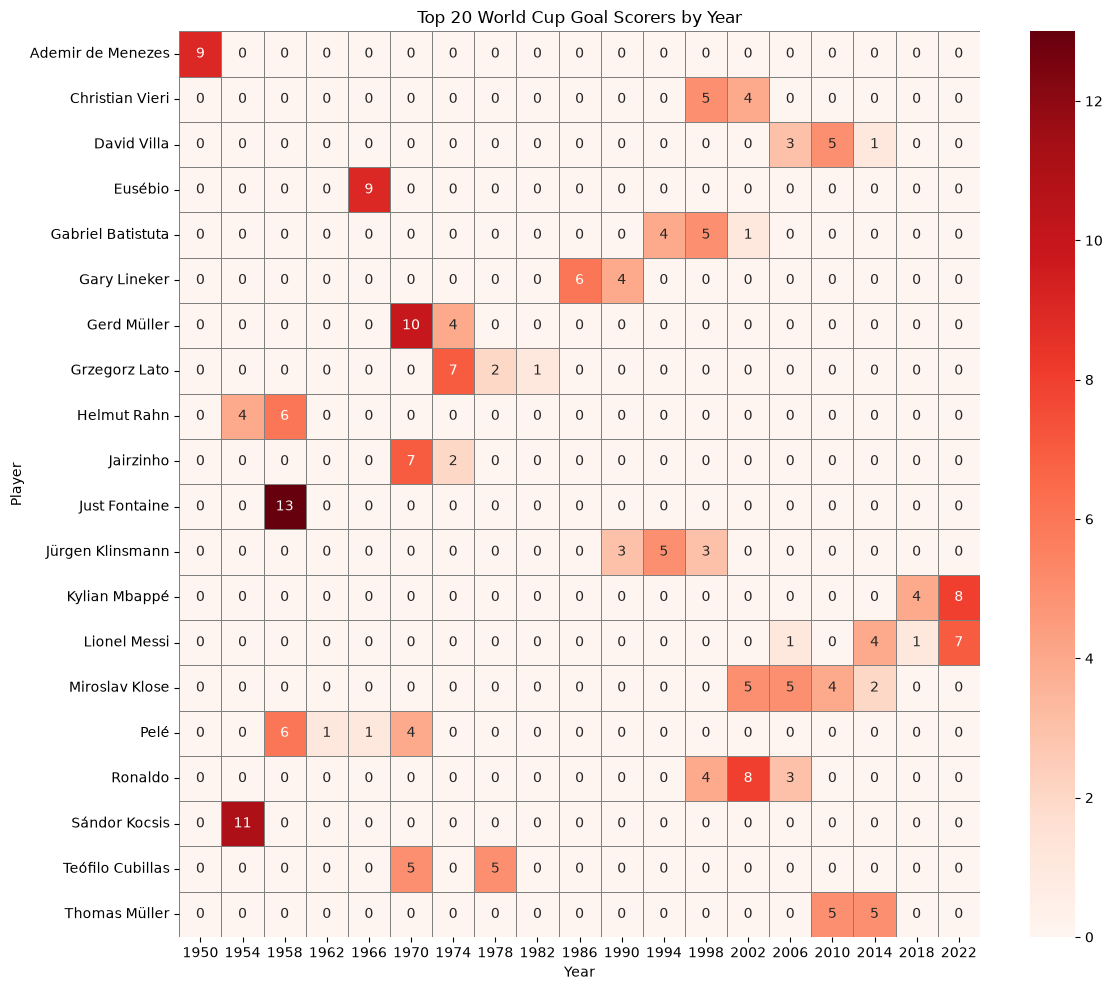

In [19]:
# Filter for World Cup matches only, merge with goalscorers, and extract year for heatmap
wc_results = results[results['tournament'] == 'FIFA World Cup'][['date', 'home_team', 'away_team']]
goals_wc = goalscorers.merge(wc_results, on=['date', 'home_team', 'away_team'], how='inner')
goals_wc['year'] = goals_wc['date'].dt.year

# Count goals per player per year and get top 20 scorers. Pulled isin method from Codecademy lesson and had copilot help troubleshoot the code to get it to work properly.
player_year_goals = goals_wc.groupby(['scorer', 'year']).size().reset_index(name='goals')
top20_scorers = player_year_goals.groupby('scorer')['goals'].sum().nlargest(20).index
top20_data = player_year_goals[player_year_goals['scorer'].isin(top20_scorers)]

# Pivot table for the heatmap
pivot = top20_data.pivot(index='scorer', columns='year', values='goals').fillna(0)

# Plot the heatmap
plt.figure(figsize=(12, 10))
sns.heatmap(pivot, cmap='Reds', annot=True, fmt='g', linewidths=0.5, linecolor='gray')
plt.title('Top 20 World Cup Goal Scorers by Year')
plt.xlabel('Year')
plt.ylabel('Player')
plt.tight_layout()
plt.savefig('top20_wc_scorers_heatmap.png')
plt.show()


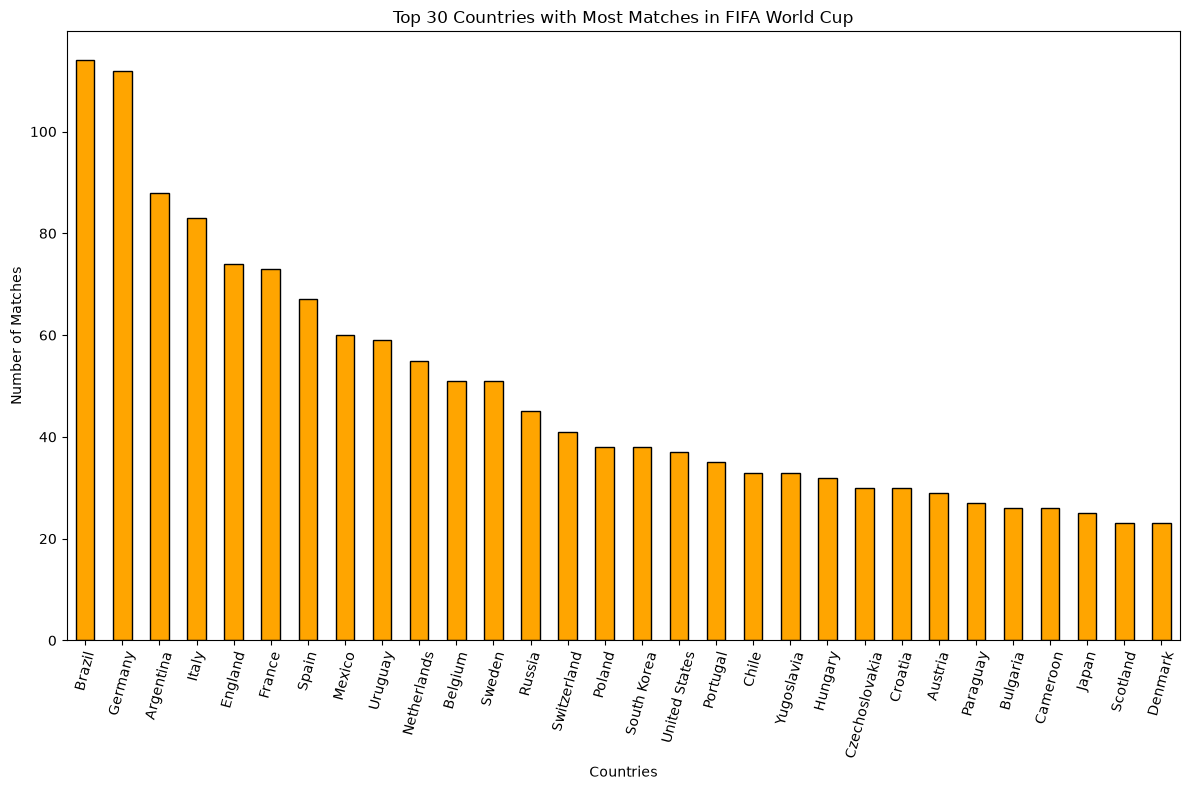

In [20]:
#Plotting the top 30 countries with the most matches in FIFA World Cup
#There are 30 countries in this graph to capture a couple countries that no longer exist (Czechoslovakia and Yugoslavia)
"""
The three lines below were suggest by copilot in addition to the plotting code beneath the comment.
plt.style.use('ggplot')
country_counts = df_WC['home_team'].value_counts().add(df_WC['away_team'].value_counts(), fill_value=0)
print(country_counts.sort_values(ascending=False).head(10))
"""

plt.figure(figsize=(12, 8))
top_countries = country_counts.sort_values(ascending=False).head(30)

# Creating a variable for the colors in the bar chart.
# Attempted colors schemes virdis and tab10 in addition to tab 20. 


top_countries.plot(kind='bar', color= "orange", edgecolor='black')
plt.title('Top 30 Countries with Most Matches in FIFA World Cup')
plt.xlabel('Countries')
plt.ylabel('Number of Matches')
plt.xticks(rotation=75)
plt.tight_layout()
plt.savefig('top30_wc_countries.png')
plt.show()


In [21]:
# Function to get match results by country - This was suggested by copilot. I originally thought about using a for loop, but found the function better for examining each individual country. 
def get_match_results_by_country(country):
        
    country_results = df_WC[(df_WC['home_team'] == country) | (df_WC['away_team'] == country)]
    return country_results

get_match_results_by_country('United States')  # Example usage to get results for the United States

,match_date,home_team,away_team,home_score,away_score,tournament,winner
0,1930-07-13,Belgium,United States,0,3,FIFA World Cup,NaN
7,1930-07-17,Paraguay,United States,0,3,FIFA World Cup,NaN
15,1930-07-26,Argentina,United States,6,1,FIFA World Cup,NaN
24,1934-05-27,Italy,United States,7,1,FIFA World Cup,NaN
56,1950-06-25,Spain,United States,3,1,FIFA World Cup,NaN
61,1950-06-29,England,United States,0,1,FIFA World Cup,NaN
65,1950-07-02,Chile,United States,5,2,FIFA World Cup,NaN
418,1990-06-10,United States,Czechoslovakia,1,5,FIFA World Cup,NaN
426,1990-06-14,Italy,United States,1,0,FIFA World Cup,NaN
438,1990-06-19,Austria,United States,2,1,FIFA World Cup,NaN


In [22]:
# Creating a new dataframe only from the results dataframe 

def get_match_results(row):

    #Determine match outcomes, including shootouts
    if row['home_score'] > row['away_score']:
        return pd.Series({'home_result' : 'Win', 'away_result' : 'Loss'})
    elif row['home_score'] < row['away_score']:
        return pd.Series({'home_result' : 'Loss', 'away_result' : 'Win'})
    else:
        # Draw in regular time; check for shootout
        if pd.notna(row['winner']):
            # Fix: compare the shootout winner (not the home score) to the home team
            if row['winner'] == row['home_team']:
                return pd.Series({'home_result': 'Win', 'away_result': 'Loss'})
            elif row['winner'] == row['away_team']:
                return pd.Series({'home_result': 'Loss', 'away_result': 'Win'})
        return pd.Series({'home_result': 'Draw', 'away_result': 'Draw'})

# Apply the function to create result columns
df_WC[['home_result', 'away_result']] = df_WC.apply(get_match_results, axis=1)
df_WC['year'] = df_WC['match_date'].dt.year


# Reshape the data by creating new dataframs for home and away teams for each team's perspective in order to analyze records by country
home_df_WC = df_WC[['year', 'home_team', 'home_result']].copy() # .copy() came from copilot and I was not aware of this feature
home_df_WC.columns = ['year', 'team', 'result']
away_df_WC = df_WC[['year', 'away_team', 'away_result']].copy()
away_df_WC.columns = ['year', 'team', 'result']
combined_df_WC = pd.concat([home_df_WC, away_df_WC], ignore_index=True)


# Aggregate the results
records = combined_df_WC.groupby(['team', 'year', 'result']).size().unstack(fill_value=0).reset_index()
records = records.reindex(columns=['team', 'year', 'Win', 'Loss', 'Draw'], fill_value=0) #reindexing to ensure all columns are present, this was from copilot.
records = records.reset_index()#.rename(columns={'team': 'Country'})


# Added a try/except block to handle potential errors when checking for a country that does not exist in the records dataframe.
try:
    country = input("Enter a country name: ")
    country_records = records[records['team'] == country]
    if country_records.empty:
        raise ValueError(f"No records found for {country}.")
    print(country_records)
except ValueError:
    print("Please enter a valid country.")


Enter a country name: France
result  index    team  year  Win  Loss  Draw
163       163  France  1930    1     2     0
164       164  France  1934    0     1     0
165       165  France  1938    1     1     0
166       166  France  1954    1     1     0
167       167  France  1958    4     2     0
168       168  France  1966    0     2     1
169       169  France  1978    1     2     0
170       170  France  1982    3     3     1
171       171  France  1986    5     1     1
172       172  France  1998    7     0     0
173       173  France  2002    0     2     1
174       174  France  2006    4     1     2
175       175  France  2010    0     2     1
176       176  France  2014    3     1     1
177       177  France  2018    6     0     1
178       178  France  2022    5     2     0


In [23]:
# Code testing above to check for United States records
US_records = records[records['team'] == 'United States']
print(US_records)


result  index           team  year  Win  Loss  Draw
454       454  United States  1930    2     1     0
455       455  United States  1934    0     1     0
456       456  United States  1950    1     2     0
457       457  United States  1990    0     3     0
458       458  United States  1994    1     2     1
459       459  United States  1998    0     3     0
460       460  United States  2002    2     2     1
461       461  United States  2006    0     2     1
462       462  United States  2010    1     1     2
463       463  United States  2014    1     2     1
464       464  United States  2022    1     1     2


The code below counted the number of goals scored in total for the World Cup. This does not account for the differentiated number of World Cups each country has played in for the history of this tournament. It is just a raw count of the goals scored by each country. 



In [24]:
# Total goals scored by each country in the World Cup

#Sum of home and away goals for each match
home_goals = df_WC.groupby('home_team')['home_score'].sum()
away_goals = df_WC.groupby('away_team')['away_score'].sum()

#Combine the home and away goals to get total goals scored by each country and sort values in descending. Using fill_value to fill any missing data. 
total_goals = home_goals.add(away_goals, fill_value=0).sort_values(ascending=False)

goals_by_country = total_goals.reset_index()
goals_by_country.columns = ['country', 'total_goals']
#total_goals.columns = ['country', 'goals']

#Rounding to 0 decimal places for readability and converting to integer since dealing with a whole number.
#total_goals['goals'] = total_goals['goals'].round(0).astype(int)

print(total_goals.head(10))



home_team
Brazil         237.0
Germany        232.0
Argentina      152.0
France         136.0
Italy          128.0
Spain          108.0
England        104.0
Netherlands     96.0
Uruguay         89.0
Hungary         87.0
dtype: float64


In [25]:
#Average number of shootouts per World Cup
# Fix: only count matches that actually had a shootout (a winner is listed). Before this fix the code counted every match.
wc_shootouts = df_WC[df_WC['winner'].notna()]
all_wc_years = sorted(df_WC['match_date'].dt.year.unique())

# Group by year and count the number of shootouts. Fix: reindex so World Cups with zero shootouts still count as 0.
shootouts_per_year = wc_shootouts['match_date'].dt.year.value_counts().reindex(all_wc_years, fill_value=0).sort_index()
shootouts_per_year.index.name = 'year'

average_shootouts = shootouts_per_year.mean()
print(f"Total shootouts in World Cup matches: {shootouts_per_year.sum()}")
print(f"Average number of shootouts per World Cup: {average_shootouts:.2f}")
print(f"Number of shootouts per World Cup year:")
print(shootouts_per_year)

# Fix: the old numbers were really matches per tournament, so they are kept here with the correct label.
matches_per_year = df_WC['match_date'].dt.year.value_counts().sort_index()
print(f"Number of matches per World Cup year:")
print(matches_per_year)

Total shootouts in World Cup matches: 35
Average number of shootouts per World Cup: 1.59
Number of shootouts per World Cup year:
year
1930    0
1934    0
1938    0
1950    0
1954    0
1958    0
1962    0
1966    0
1970    0
1974    0
1978    0
1982    1
1986    3
1990    4
1994    3
1998    3
2002    2
2006    4
2010    2
2014    4
2018    4
2022    5
Name: count, dtype: int64
Number of matches per World Cup year:
match_date
1930    18
1934    17
1938    18
1950    22
1954    26
1958    35
1962    32
1966    32
1970    32
1974    38
1978    38
1982    52
1986    52
1990    52
1994    52
1998    64
2002    64
2006    64
2010    64
2014    64
2018    64
2022    64
Name: count, dtype: int64


Code below is for a bar graph for the number of shootouts in each World Cup tournament.

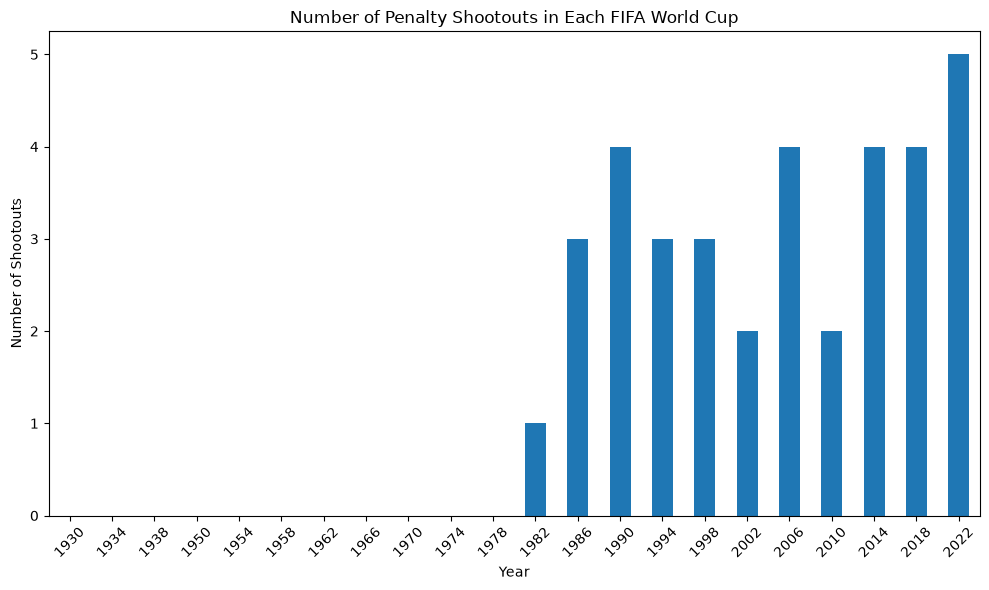

In [26]:
# Bar graph plotting the number of shootouts per year in World Cup matches.
df_WC['year'] = df_WC['match_date'].dt.year
plt.figure(figsize=(10, 6))
# Fix: plot the shootout counts from above instead of the number of matches
shootouts_per_year.plot(kind='bar')
plt.title('Number of Penalty Shootouts in Each FIFA World Cup')
plt.xlabel('Year')
plt.ylabel('Number of Shootouts')
plt.yticks(range(0, shootouts_per_year.max() + 1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('shootouts_per_year.png')
plt.show()


Code below is for the same date as above, but for a line chart.

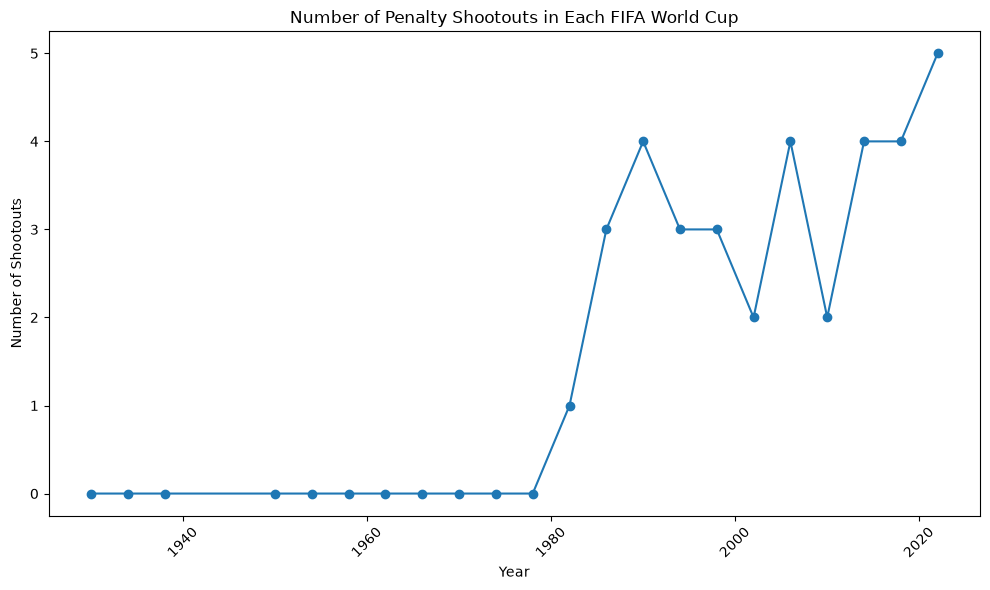

In [27]:
# Line chart for the number of shootouts in each World Cup tournament.

df_WC['year'] = df_WC['match_date'].dt.year
plt.figure(figsize=(10, 6))
# Fix: plot the shootout counts from above instead of the number of matches
shootouts_per_year.plot(kind='line', marker='o')
plt.title('Number of Penalty Shootouts in Each FIFA World Cup')  
plt.xlabel('Year')
plt.ylabel('Number of Shootouts')
plt.yticks(range(0, shootouts_per_year.max() + 1))
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('shootouts_per_year_line.png')
plt.show()